# Notebook 08 — Cone perception: detector, simulated detector, memory, error model

Companion to [Chapter 9](../09_perception_driven_racing.md). Uses 40 real frames from Gazebo's simulated OAK-D
(`../data/gazebo_cone_frames`, with the car's true pose for each) to build and score the detector, compare
ranging methods, fit a detector error model, and see why the policy needs memory in a tight bend.

*Track layout.* These frames were recorded when the racetrack had 1.2 m gates, so the notebook loads that
layout (`../data/gazebo_cone_frames/racetrack_1.2m_gates.world`). The racetrack now has 2.2 m gates and extra
gates in the bends (Chapter 9, section 8); the method is unchanged, and refitting on new frames is exercise 4.

In [1]:
import warnings; warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sys, math, csv
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, cv2
WS = Path('../../..').resolve(); sys.path.insert(0, str(WS / 'src' / 'saurcon_rl'))
from saurcon_rl.cones import ConeDetector
from saurcon_rl.cone_env import visible_cones, ConeMemory, encode, CAMERA_X, HALF_FOV, MAX_RANGE
from saurcon_rl.track import Track
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
DATA = Path('../data/gazebo_cone_frames')
# The frames were recorded on the original 1.2 m gates; the racetrack now has 2.2 m gates plus bend gates.
# Score them against the layout they were recorded on, kept next to them.
track = Track.from_world(DATA / 'racetrack_1.2m_gates.world')
poses = list(csv.DictReader(open(DATA / 'poses.csv')))
FX = 320 / math.tan(1.204 / 2)
print(f'{len(poses)} Gazebo frames, {len(track.cones)} cones on the racetrack')

40 Gazebo frames, 84 cones on the racetrack


## 1. The detector, step by step

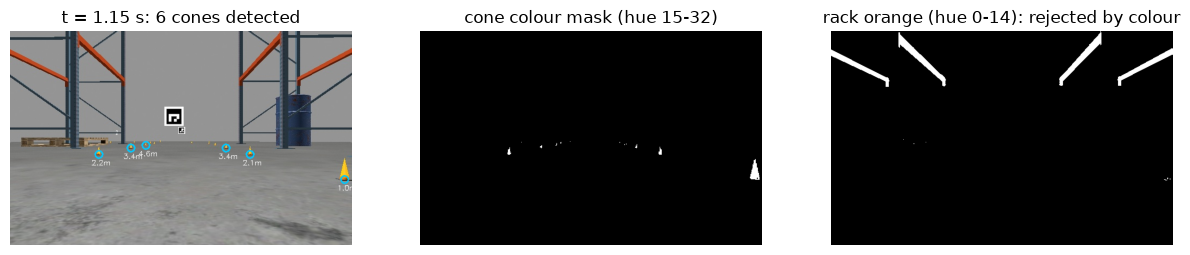

In [2]:
p = poses[20]; img = cv2.imread(str(DATA / p['frame']))
det = ConeDetector(FX, FX, 320, 200, camera_height=0.137)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, det.hsv_lo, det.hsv_hi)
racks = cv2.inRange(hsv, (0, 120, 60), (14, 255, 255))        # deeper orange: the racks
dets = det.detect(img)
over = img.copy()
for d in dets:
    cv2.circle(over, (int(d.u), int(d.v)), 7, (255, 200, 0), 2)
    cv2.putText(over, f'{d.range:.1f}m', (int(d.u) - 14, int(d.v) + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].imshow(cv2.cvtColor(over, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"t = {p['t']} s: {len(dets)} cones detected")
ax[1].imshow(mask, cmap='gray'); ax[1].set_title('cone colour mask (hue 15-32)')
ax[2].imshow(racks, cmap='gray'); ax[2].set_title('rack orange (hue 0-14): rejected by colour')
for a in ax: a.axis('off')
plt.show()

## 2. Ranging methods against ground truth
For every frame, match each detection to the true cone at the same bearing and compare forward distance.

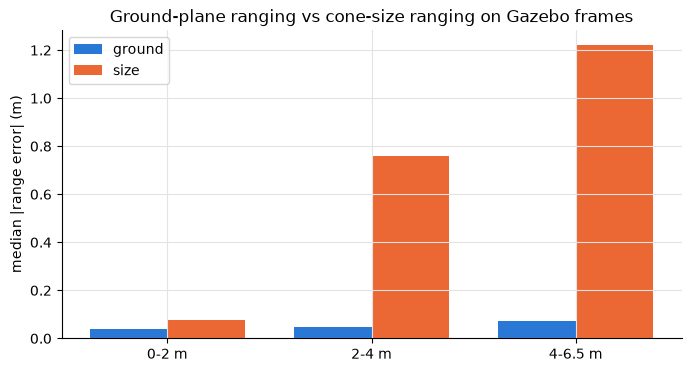

In [3]:
def truth_cam(p):
    """True cones in the camera-centred base frame (x forward from base_link, y left), noise-free."""
    return visible_cones(track.cones, float(p['x']), float(p['y']), float(p['yaw']), noise=False)

def associate(truth, dets, max_bearing=0.02, max_rel_range=0.3):
    """Pair detections with true cones by bearing AND range. Bearing alone is not enough: along a straight,
    cones on one side line up at almost the same bearing, and far detections get paired with the wrong cone."""
    tr_ = np.hypot(truth[:, 0] - CAMERA_X, truth[:, 1]); tb = np.arctan2(truth[:, 1], truth[:, 0] - CAMERA_X)
    pairs, used = [], set()
    for d in dets:
        b = math.atan2(-d.p_cam[0], d.p_cam[2]); r = math.hypot(d.p_cam[0], d.p_cam[2])
        ok = np.where((abs(tb - b) < max_bearing) & (abs(tr_ - r) < max_rel_range * tr_))[0]
        ok = [j for j in ok if j not in used]
        if ok:
            j = min(ok, key=lambda j: abs(tb[j] - b)); used.add(j); pairs.append((j, d))
    return pairs, used

rows = []
for p in poses:
    img = cv2.imread(str(DATA / p['frame'])); truth = truth_cam(p)
    if not len(truth): continue
    for method, d_ in (('ground', ConeDetector(FX, FX, 320, 200, camera_height=0.137)),
                       ('size', ConeDetector(FX, FX, 320, 200))):
        pairs, _ = associate(truth, d_.detect(img), max_rel_range=0.6)   # loose gate: size ranging can be far off
        for j, d in pairs:
            rows.append((method, truth[j, 0] - CAMERA_X, d.p_cam[2] - (truth[j, 0] - CAMERA_X)))
R = np.array([(r[1], r[2]) for r in rows]); M = np.array([r[0] for r in rows])
bins = [(0, 2), (2, 4), (4, 6.5)]
x = np.arange(len(bins)); w = 0.38
for k, (m, c) in enumerate((('ground', BLUE), ('size', ORANGE))):
    med = [np.median(np.abs(R[(M == m) & (R[:, 0] >= lo) & (R[:, 0] < hi), 1])) for lo, hi in bins]
    plt.bar(x + (k - 0.5) * w, med, w, color=c, label=m)
plt.xticks(x, [f'{lo}-{hi} m' for lo, hi in bins]); plt.ylabel('median |range error| (m)'); plt.legend()
plt.title('Ground-plane ranging vs cone-size ranging on Gazebo frames'); plt.show()

## 3. The simulated detector used in training
What the policy is trained on: every cone in the field of view and range, with misses and range noise.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


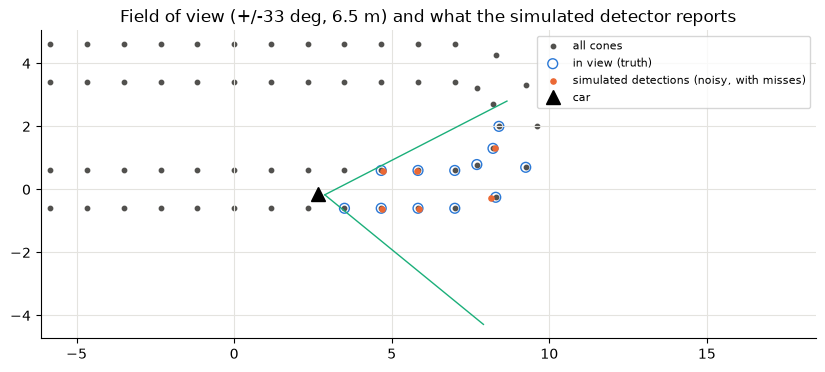

In [4]:
p = poses[25]; x0, y0, yaw0 = float(p['x']), float(p['y']), float(p['yaw'])
rng = np.random.default_rng(0)
sim = visible_cones(track.cones, x0, y0, yaw0, rng, noise=True)
c, s = math.cos(yaw0), math.sin(yaw0)
to_world = lambda q: np.column_stack([x0 + c*q[:, 0] - s*q[:, 1], y0 + s*q[:, 0] + c*q[:, 1]])
plt.figure(figsize=(10, 4))
plt.scatter(track.cones[:, 0], track.cones[:, 1], s=10, color=GREY, label='all cones')
cx, cy = x0 + CAMERA_X*c, y0 + CAMERA_X*s
for sgn in (1, -1):
    a = yaw0 + sgn*HALF_FOV; plt.plot([cx, cx + MAX_RANGE*math.cos(a)], [cy, cy + MAX_RANGE*math.sin(a)], color=AQUA, lw=1)
plt.scatter(*to_world(truth_cam(p)).T, s=50, facecolors='none', edgecolors=BLUE, label='in view (truth)')
plt.scatter(*to_world(sim).T, s=14, color=ORANGE, label='simulated detections (noisy, with misses)')
plt.plot(x0, y0, 'k^', ms=10, label='car'); plt.axis('equal'); plt.xlim(x0 - 1, x0 + 8); plt.legend(fontsize=8)
plt.title('Field of view (+/-33 deg, 6.5 m) and what the simulated detector reports'); plt.show()

## 4. Why memory: cones in view through the first bend
Drive the true racetrack centreline at 3 m/s and count the cones the policy observes with no memory and with
a 2 s memory.

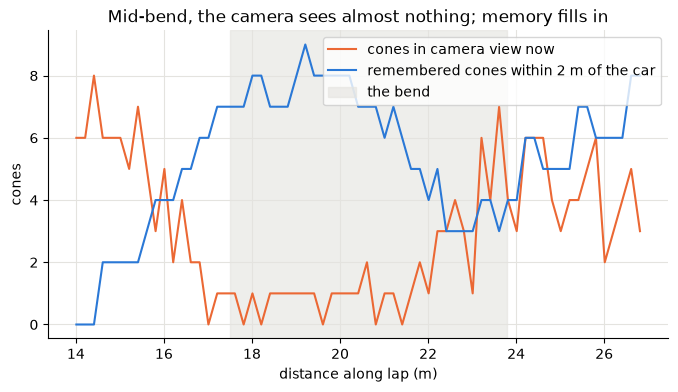

In [5]:
sel = (track.s > 14) & (track.s < 27)                          # into, through and out of the first bend
idx = np.where(sel)[0][::20]
mem = ConeMemory(); counts = []
for n, i in enumerate(idx):
    t = n * (track.s[idx[1]] - track.s[idx[0]]) / 3.0
    x, y, yaw = track.xy[i, 0], track.xy[i, 1], track.heading[i]
    seen = visible_cones(track.cones, x, y, yaw, rng, noise=True)
    c, s = math.cos(yaw), math.sin(yaw)
    mem.update(np.column_stack([x + c*seen[:, 0] - s*seen[:, 1], y + s*seen[:, 0] + c*seen[:, 1]]), t)
    rel, ages = mem.relative(x, y, yaw, t)
    near = np.hypot(*rel.T) < 2.0
    counts.append((track.s[i], len(seen), int(near.sum())))
C = np.array(counts)
plt.plot(C[:, 0], C[:, 1], color=ORANGE, label='cones in camera view now')
plt.plot(C[:, 0], C[:, 2], color=BLUE, label='remembered cones within 2 m of the car')
plt.axvspan(17.5, 17.5 + 2*np.pi, color='#e4e3df', alpha=0.6, label='the bend')
plt.xlabel('distance along lap (m)'); plt.ylabel('cones'); plt.legend(); plt.title('Mid-bend, the camera sees almost nothing; memory fills in'); plt.show()

## 5. Fitting a detector error model (procedure 7.1)
Using the ground-plane detections: fit the range-error spread vs range and the miss rate vs range, then compare
with the hand-set training model. Spread is measured robustly (1.4826 x median absolute deviation) so a few
mis-associations cannot dominate. A first version of this cell matched by bearing only and "found" a 1.2 m
spread at 5 m: the metric decided the answer, not the detector.

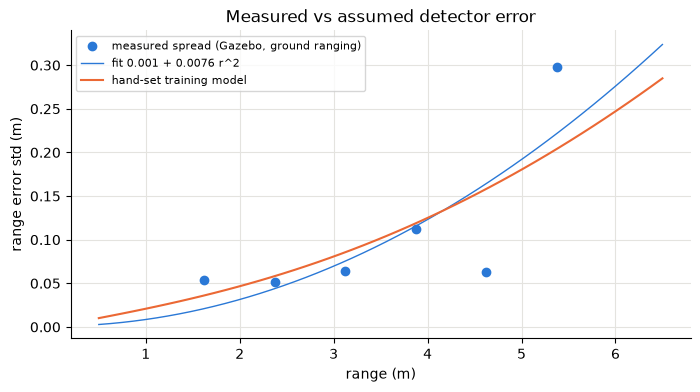

miss rate by range bin (m): {'0-1': 1.0, '1-2': 0.77, '2-3': 0.25, '3-4': 0.11, '4-5': 0.49, '5-6': 0.85}
first, hand-set model at 1, 3, 5 m: [0.05, 0.08, 0.14]
model now used in training (from this measurement): {0.5: 0.9, 1.5: 0.75, 2.5: 0.25, 3.5: 0.12, 4.5: 0.45, 5.5: 0.8, 6.5: 0.9}


In [6]:
g = R[M == 'ground']
centres, sd = [], []
for lo in np.arange(0.5, 6.5, 0.75):
    s_ = (g[:, 0] >= lo) & (g[:, 0] < lo + 0.75)
    if s_.sum() >= 5:
        e = g[s_, 1]; centres.append(lo + 0.375); sd.append(1.4826 * np.median(np.abs(e - np.median(e))))
centres, sd = np.array(centres), np.array(sd)
(c2, a0), *_ = np.linalg.lstsq(np.column_stack([centres**2, np.ones_like(centres)]), sd, rcond=None)   # a + c r^2
rr = np.linspace(0.5, 6.5, 50)
plt.plot(centres, sd, 'o', color=BLUE, label='measured spread (Gazebo, ground ranging)')
plt.plot(rr, a0 + c2*rr**2, color=BLUE, lw=1, label=f'fit {a0:.3f} + {c2:.4f} r^2')
plt.plot(rr, np.sqrt((0.02*rr)**2 + (0.006*rr**2)**2), color=ORANGE, label='hand-set training model')
plt.xlabel('range (m)'); plt.ylabel('range error std (m)'); plt.legend(fontsize=8); plt.title('Measured vs assumed detector error'); plt.show()
# miss rate: true cones in view with no matching ground-plane detection
seen_n = np.zeros(6); miss_n = np.zeros(6); det_g = ConeDetector(FX, FX, 320, 200, camera_height=0.137)
for p in poses:
    truth = truth_cam(p)
    if not len(truth): continue
    _, used = associate(truth, det_g.detect(cv2.imread(str(DATA / p['frame']))))
    for j, q in enumerate(truth):
        k = min(int(math.hypot(q[0] - CAMERA_X, q[1])), 5)
        seen_n[k] += 1; miss_n[k] += j not in used
print('miss rate by range bin (m):', {f'{k}-{k+1}': round(miss_n[k]/seen_n[k], 2) for k in range(6) if seen_n[k]})
print('first, hand-set model at 1, 3, 5 m:', [round(0.05 + 0.15*(r/6.5)**2, 2) for r in (1, 3, 5)])
from saurcon_rl.cone_env import MISS_RANGES, MISS_PROB
print('model now used in training (from this measurement):', dict(zip(MISS_RANGES.tolist(), MISS_PROB.tolist())))

With 40 frames the fit is noisy; the procedure is the point. Two things to look for in the result: whether the
measured spread grows faster with range than the training model assumes, and whether near cones are missed
more often — the 1.2 m gates put the nearest cones at about +/-31 deg, at the edge of the +/-33 deg view, where
they are partly cut off. Exercise 4 of chapter 9 asks you to repeat it
over full laps and replace the constants in `visible_cones()` with the fitted functions.

## Exercises
1. Change the hue band to 0–32 in section 1. What does the detector pick up, and which later filter rejects it?
2. In section 4, try memory horizons of 0.5, 1 and 4 s. What goes wrong when the horizon is too long?
3. Add occlusion (chapter 9, 7.2) to `visible_cones()` and rerun section 3.